**practica #5:**

**Introducción al análisis frecuencial de señales**

**presentado por:**
Karly Tarazona, Luis Montoya 

1	Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente. 

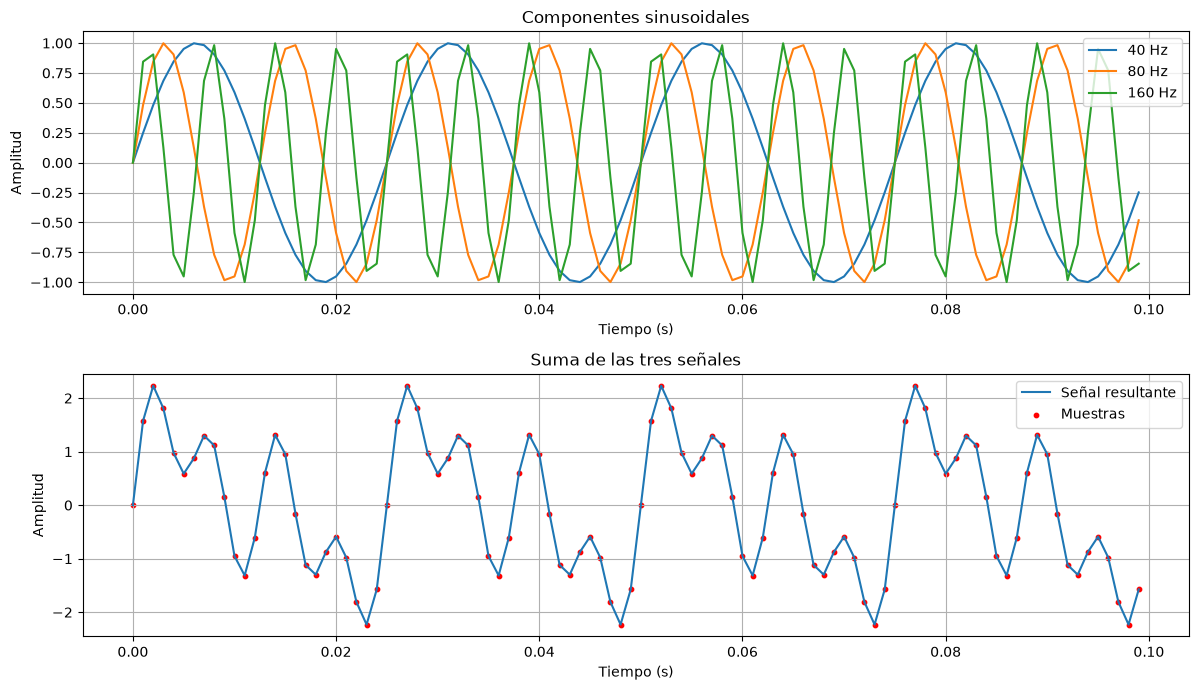

Frecuencia mínima: 320 Hz
Frecuencia utilizada: 1000 Hz


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Frecuencias de las componentes
f1 = 40
f2 = 80
f3 = 160

# Frecuencia mínima de Nyquist
fs_min = 2 * max(f1, f2, f3)

# Frecuencia de muestreo seleccionada
fs = 1000

# Vector de tiempo (0.1 segundos)
t = np.arange(0, 0.1, 1/fs)

# Componentes sinusoidales
x1 = np.sin(2 * np.pi * f1 * t)
x2 = np.sin(2 * np.pi * f2 * t)
x3 = np.sin(2 * np.pi * f3 * t)

# Señal resultante
x = x1 + x2 + x3

# Gráficas
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x1, label="40 Hz")
plt.plot(t, x2, label="80 Hz")
plt.plot(t, x3, label="160 Hz")
plt.title("Componentes sinusoidales")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, x, label="Señal resultante")
plt.scatter(t, x, s=10, color="red", label="Muestras")
plt.title("Suma de las tres señales")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Frecuencia mínima:", fs_min, "Hz")
print("Frecuencia utilizada:", fs, "Hz")


Se creó una señal mediante la suma de tres componentes sinusoidales de 40 Hz, 80 Hz y 160 Hz. Aplicando el teorema de Nyquist-Shannon, se determinó que la frecuencia mínima teórica de muestreo es de 320 Hz. No obstante, se seleccionó una frecuencia de 1000 Hz para obtener una representación digital más adecuada de la señal, con mayor cantidad de muestras y evitando las limitaciones de trabajar exactamente en la frecuencia de Nyquist.

2	Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).

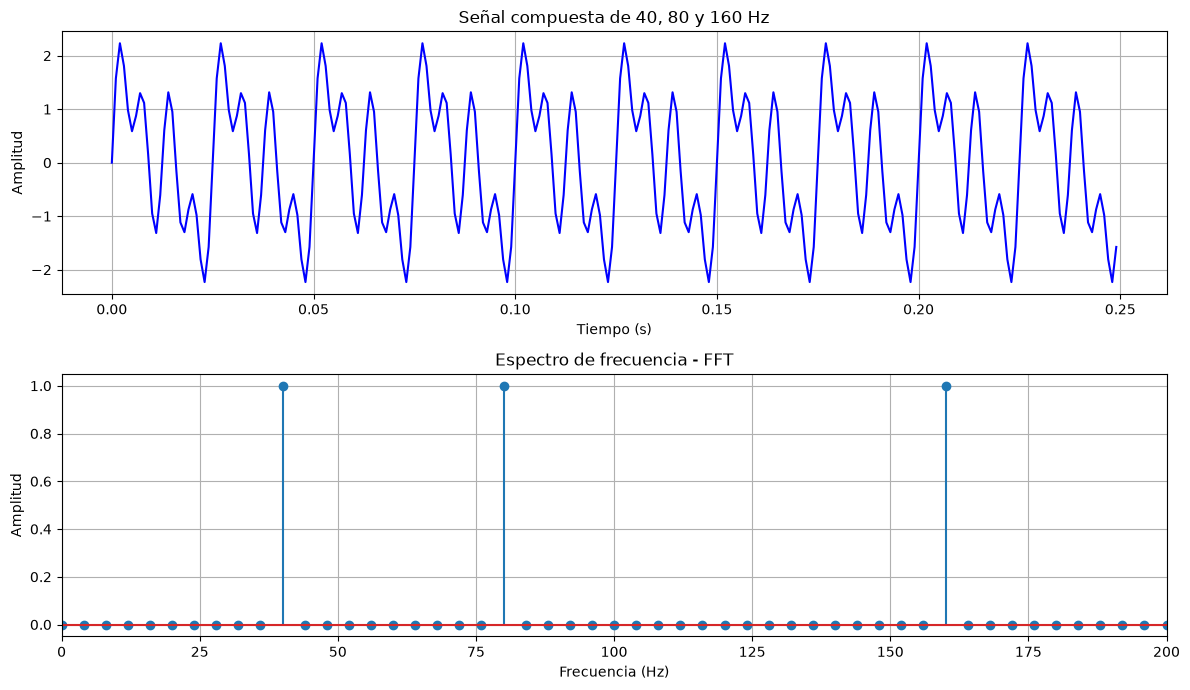

Muestras de tiempo: 250
Muestras de la señal: 250
Número de muestras FFT: 250
Resolución en frecuencia: 4.0 Hz


In [3]:
# Frecuencias de las componentes
f1 = 40
f2 = 80
f3 = 160

# Parámetros de muestreo
Fs = 1000
Fo = 40
Tp = 1/Fo
T = 1/Fs

# Vector de tiempo para 10 períodos
t = np.arange(0, 10*Tp, T)

# CREAR NUEVAMENTE LA SEÑAL ORIGINAL
x = (np.sin(2*np.pi*f1*t) +
     np.sin(2*np.pi*f2*t) +
     np.sin(2*np.pi*f3*t))

# Calcular la Transformada de Fourier
X = np.fft.fft(x)

# Número de muestras
N = len(X)

# Eje de frecuencias
F = np.arange(0, N)*Fs/N

# Seleccionar la mitad positiva del espectro
Nmitad = N//2 + 1
Fmitad = F[0:Nmitad]
Xmitad = X[0:Nmitad]

# Normalizar amplitudes
amplitud = 2*np.abs(Xmitad)/N
amplitud[0] /= 2

if N % 2 == 0:
    amplitud[-1] /= 2

# Graficar señal original y espectro
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal compuesta de 40, 80 y 160 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.stem(Fmitad, amplitud)
plt.title('Espectro de frecuencia - FFT')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 200)
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar resultados
print("Muestras de tiempo:", len(t))
print("Muestras de la señal:", len(x))
print("Número de muestras FFT:", N)
print("Resolución en frecuencia:", Fs/N, "Hz")


3	Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal 

La Transformada Inversa de Fourier permite reconstruir una señal en el dominio del tiempo a partir de su representación en el dominio de la frecuencia.
En Python, la función que permite realizar este cálculo es **`np.fft.ifft()`**. Donde \(N\) representa el número de muestras y \(X[k]\) los coeficientes de Fourier

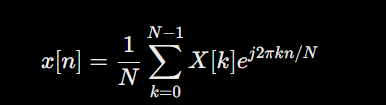

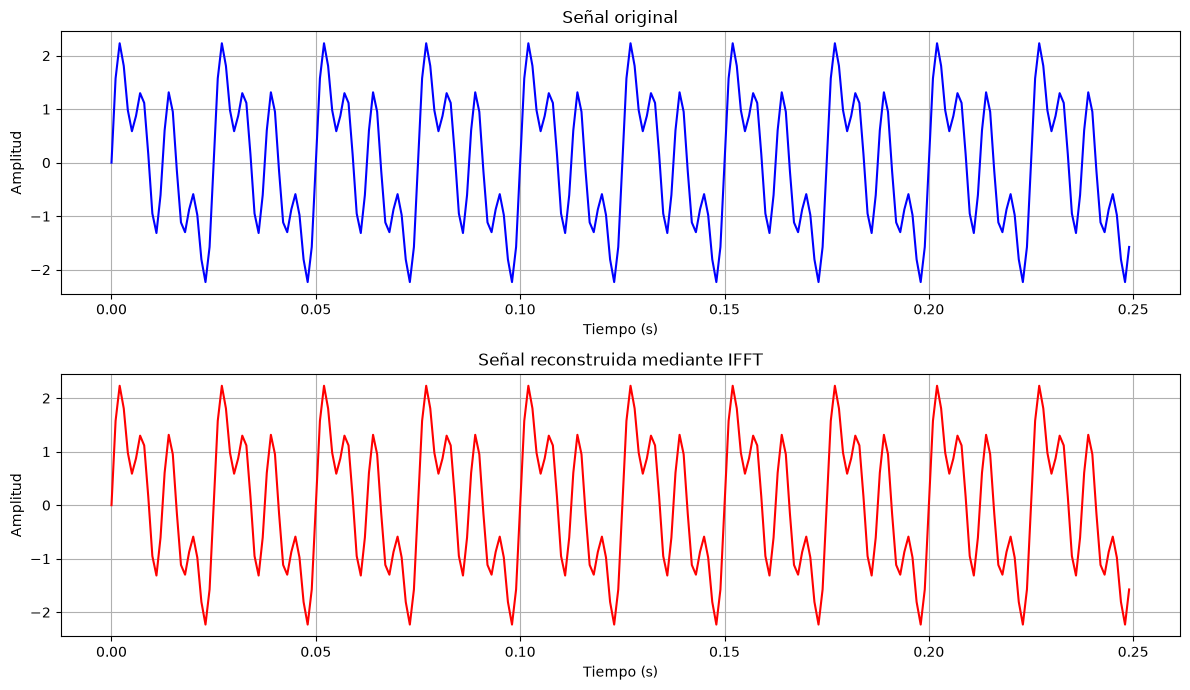

Error máximo de reconstrucción: 8.881784197001252e-16


In [4]:
# Transformada inversa de Fourier
xr = np.fft.ifft(X)

# Parte real de la señal reconstruida
xr = np.real(xr)

# Comparación gráfica
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal original')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t, xr, color='red')
plt.title('Señal reconstruida mediante IFFT')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar el error de reconstrucción
error = np.max(np.abs(x - xr))
print("Error máximo de reconstrucción:", error)

se comprobó que es posible transformar una señal del dominio del tiempo al dominio de la frecuencia y posteriormente recuperarla sin pérdida apreciable de información. Las señales original y reconstruida presentan un comportamiento prácticamente idéntico, con diferencias numéricas cercanas a cero. Esto demuestra la utilidad de la transformada inversa en el procesamiento digital de señales y constituye la base para aplicar técnicas de filtrado frecuencial

4	¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?

C:\Users\Acer\AppData\Local\Temp\ipykernel_13416\2457393857.py:3: ComplexWarning: Casting complex values to real discards the imaginary part
  F2[9:13] = F1[9:13];


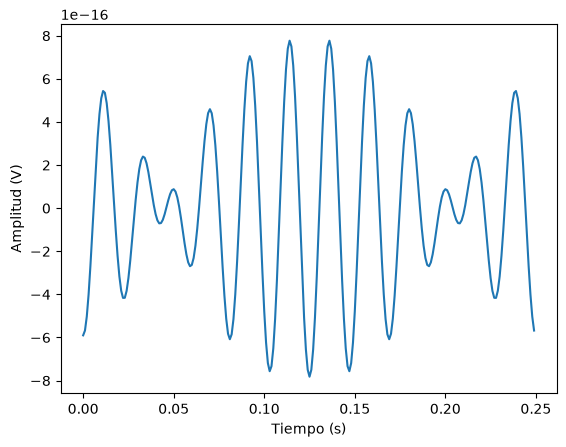

In [5]:
F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()


Sí. El código realiza un filtrado en el dominio de la frecuencia, porque selecciona determinados coeficientes de la Transformada de Fourier y elimina los demás.

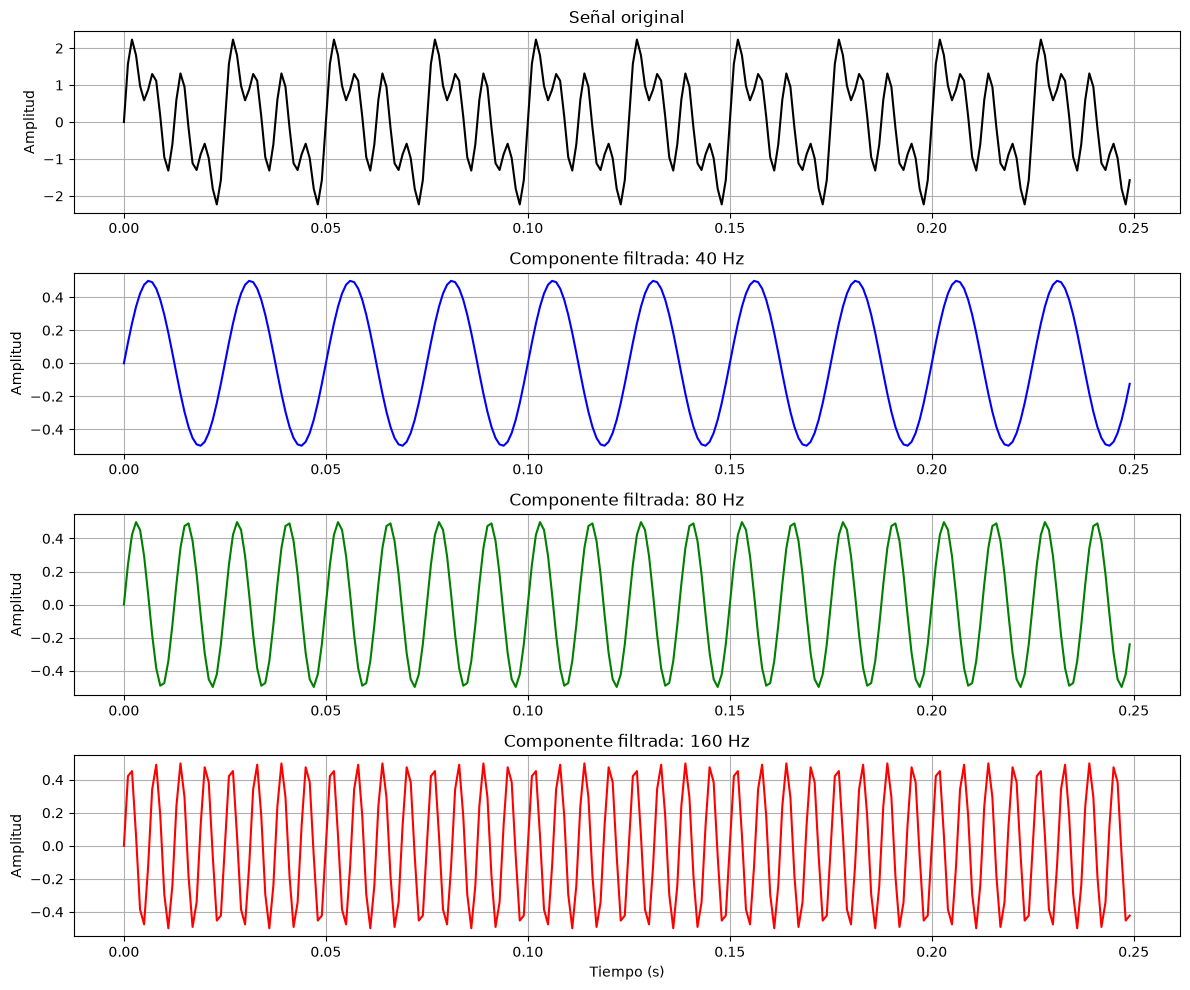

Error máximo: 1.1154543260348764


In [6]:

# Filtrar componente de 40 Hz
F40 = np.zeros(N, dtype=complex)
F40[np.isclose(np.abs(F), 40)] = F1[
    np.isclose(np.abs(F), 40)
]
x40 = np.real(np.fft.ifft(F40))

# Filtrar componente de 80 Hz
F80 = np.zeros(N, dtype=complex)
F80[np.isclose(np.abs(F), 80)] = F1[
    np.isclose(np.abs(F), 80)
]
x80 = np.real(np.fft.ifft(F80))

# Filtrar componente de 160 Hz
F160 = np.zeros(N, dtype=complex)
F160[np.isclose(np.abs(F), 160)] = F1[
    np.isclose(np.abs(F), 160)
]
x160 = np.real(np.fft.ifft(F160))

# Graficar resultados
plt.figure(figsize=(12, 10))

plt.subplot(4, 1, 1)
plt.plot(t, x, color='black')
plt.title('Señal original')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, x40, color='blue')
plt.title('Componente filtrada: 40 Hz')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x80, color='green')
plt.title('Componente filtrada: 80 Hz')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(4, 1, 4)
plt.plot(t, x160, color='red')
plt.title('Componente filtrada: 160 Hz')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.tight_layout()
plt.show()

# Verificar reconstrucción
x_reconstruida = x40 + x80 + x160

error = np.max(np.abs(x - x_reconstruida))
print("Error máximo:", error)


El código propuesto aplica un filtro en el dominio de la frecuencia, ya que permite seleccionar determinados coeficientes de la Transformada Discreta de Fourier y eliminar las componentes no deseadas. A través de este procedimiento se logró extraer individualmente las señales de 40 Hz, 80 Hz y 160 Hz, conservando los coeficientes correspondientes a sus frecuencias positivas y negativas. Posteriormente, mediante la Transformada Inversa de Fourier, se reconstruyó cada componente en el dominio del tiempo. Los resultados demuestran que el análisis frecuencial permite separar señales de distintas frecuencias y recuperar sus características originales

5	Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo e una de las señales construidas anteriormente.

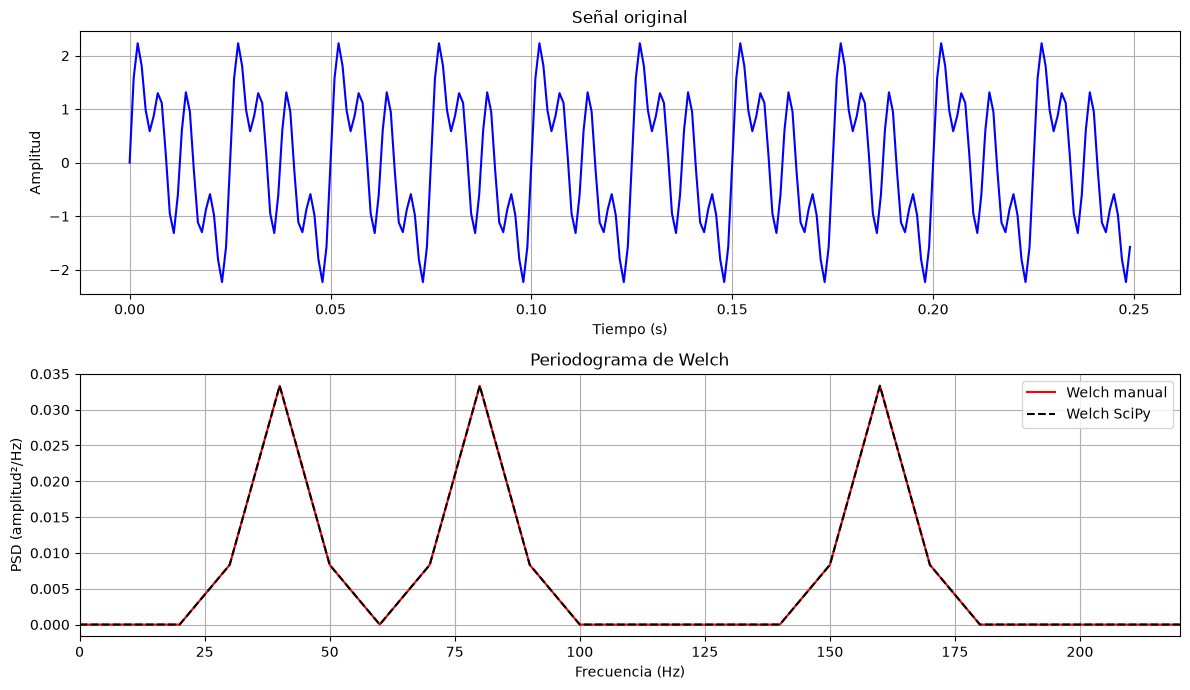

Frecuencias de interés: 40, 80 y 160 Hz
Número de segmentos: 4
Resolución: 10.0 Hz
Error máximo frente a SciPy: 1.3877787807814457e-17
40 Hz: PSD = 0.033333
80 Hz: PSD = 0.033333
160 Hz: PSD = 0.033333


In [7]:
from scipy.signal import welch

# 2. Función manual del periodograma de Welch
def welch_manual(x, Fs, L=100, solapamiento=50):

    N = len(x)
    paso = L - solapamiento

    if L > N or L <= 0:
        raise ValueError("Tamaño de segmento inválido")

    if paso <= 0 or solapamiento < 0:
        raise ValueError("Solapamiento inválido")

    # Crear ventana Hann periódica
    n = np.arange(L)
    ventana = 0.5 - 0.5*np.cos(2*np.pi*n/L)

    # Normalización de potencia de la ventana
    U = np.sum(ventana**2)

    periodogramas = []

    # Dividir la señal en segmentos
    for inicio in range(0, N-L+1, paso):

        segmento = x[inicio:inicio+L]

        # Aplicar ventana Hann
        segmento_ventana = segmento * ventana

        # Calcular DFT mediante FFT
        X = np.fft.fft(segmento_ventana)

        # Calcular periodograma bilateral
        P = (np.abs(X)**2) / (Fs*U)

        # Convertir a espectro unilateral
        P = P[:L//2+1]

        if L % 2 == 0:
            P[1:-1] *= 2
        else:
            P[1:] *= 2

        periodogramas.append(P)

    # Promediar todos los periodogramas
    PSD = np.mean(periodogramas, axis=0)

    # Crear eje de frecuencias
    frecuencias = np.fft.rfftfreq(L, d=1/Fs)

    return frecuencias, PSD

# 3. Aplicar nuestra función
F_manual, P_manual = welch_manual(x, Fs)

# 4. Comparar con la función de SciPy
F_scipy, P_scipy = welch(
    x,
    fs=Fs,
    window='hann',
    nperseg=100,
    noverlap=50,
    detrend=False,
    scaling='density'
)

# 5. Graficar
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.plot(t, x, color='blue')
plt.title('Señal original')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(F_manual, P_manual,
         label='Welch manual', color='red')
plt.plot(F_scipy, P_scipy, '--',
         label='Welch SciPy', color='black')

plt.title('Periodograma de Welch')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('PSD (amplitud²/Hz)')
plt.xlim(0, 220)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 6. Verificar resultados
print("Frecuencias de interés: 40, 80 y 160 Hz")
print("Número de segmentos:", 4)
print("Resolución:", Fs/100, "Hz")
print("Error máximo frente a SciPy:",
      np.max(np.abs(P_manual-P_scipy)))

for f in [40, 80, 160]:
    i = np.argmin(np.abs(F_manual-f))
    print(f"{f} Hz: PSD = {P_manual[i]:.6f}")


se tomo la señal en segmentos parcialmente superpuestos, y se aplico una ventana Hann. Se procedio a calcular la transformada de cada segmento, obtener su densidad espectral de potencia y promediar los resultados. Al aplicar el procedimiento a la señal construida anteriormente, se identificaron correctamente las frecuencias de 40 Hz, 80 Hz y 160 Hz. La comparación con la función Welch de SciPy confirmó la concordancia de los resultados.